# DX799 Capstone — Week 10: K-Means Clustering

K-means was applied to Statlog Heart Disease and Framingham to examine whether continuous clinical measurements form interpretable patient groups. The main question is how the number of clusters and feature scaling affect these groupings. Disease outcomes are used only for describing the completed clusters, not for constructing them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             adjusted_rand_score, pairwise_distances)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

SEED = 42
K_RANGE = range(1, 9)
SIL_SAMPLE = 1000

## 1. Datasets and variables

The analysis uses the preprocessed datasets from the earlier capstone work. The selected features are continuous measurements shared with the previous cardiovascular analyses; categorical variables and the diagnosis/CHD outcomes are excluded from clustering.

In [2]:
BASE = "https://raw.githubusercontent.com/piraterashik/DX799-Data-Science-Capstone/main/"
heart = pd.read_csv(BASE + "preprocessed_heart_disease.csv")
framingham = pd.read_csv(BASE + "preprocessed_framingham.csv")

SPEC = {
    "Statlog": {"df": heart, "target": "target",
                "features": ["age", "trestbps", "chol", "thalach", "oldpeak"]},
    "Framingham": {"df": framingham, "target": "TenYearCHD",
                   "features": ["age", "sysBP", "diaBP", "BMI", "totChol", "glucose"]}
}

for name, item in SPEC.items():
    required = item["features"] + [item["target"]]
    absent = sorted(set(required) - set(item["df"].columns))
    if absent:
        raise ValueError(f"{name}: missing columns {absent}")
    print(f"{name}: {len(item['df'])} records; {len(item['features'])} clustering variables")

Statlog: 270 records; 5 clustering variables
Framingham: 4238 records; 6 clustering variables


## 2. Exploratory analysis

Feature ranges, missingness, and extreme observations were examined before selecting a scaling method. K-means uses squared Euclidean distances, so variables with larger numeric ranges and extreme values may dominate the clusters.

In [3]:
eda_rows = []
for name, item in SPEC.items():
    df = item["df"]
    for feature in item["features"]:
        s = pd.to_numeric(df[feature], errors="coerce")
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum() if iqr > 0 else 0
        eda_rows.append({"Dataset": name, "Feature": feature, "Missing": int(s.isna().sum()),
                         "Mean": s.mean(), "SD": s.std(), "Min": s.min(), "Max": s.max(),
                         "IQR outliers": int(outliers)})
eda = pd.DataFrame(eda_rows)
display(eda.round(2))

print("Framingham sysBP–diaBP correlation:",
      round(framingham[["sysBP", "diaBP"]].corr().iloc[0, 1], 3))

,Dataset,Feature,Missing,Mean,SD,Min,Max,IQR outliers
0,Statlog,age,0,54.43,9.11,29.00,77.0,0
1,Statlog,trestbps,0,131.34,17.86,94.00,200.0,9
2,Statlog,chol,0,249.66,51.69,126.00,564.0,5
3,Statlog,thalach,0,149.68,23.17,71.00,202.0,1
4,Statlog,oldpeak,0,1.05,1.15,0.00,6.2,4
5,Framingham,age,0,49.58,8.57,32.00,70.0,0
6,Framingham,sysBP,0,132.35,22.04,83.50,295.0,126
7,Framingham,diaBP,0,82.89,11.91,48.00,142.5,81
8,Framingham,BMI,0,25.80,4.07,15.54,56.8,97
9,Framingham,totChol,0,236.69,44.33,107.00,696.0,57


Framingham sysBP–diaBP correlation: 0.784


## 3. K-means calculation: fruit example

K-means assigns each observation to the nearest centroid and updates the centroid to the mean of its members. This repeats until assignments stabilize. Within-cluster sum of squares (WCSS, or inertia) measures squared distances from observations to their centroids. Silhouette scores compare a point's average distance within its cluster, *a*, with the smallest average distance to another cluster, *b*: **(b − a) / max(a, b)**.

The arithmetic mean minimizes squared Euclidean distances; Manhattan-based clustering would instead require median-based centers.

In [4]:
fruit = pd.DataFrame({
    "Sweetness": [4, 1, 5, 3, 5, 3],
    "Sourness": [2, 5, 1, 4, 2, 3],
    "Bitterness": [1, 2, 1, 3, 1, 2],
    "Juiciness": [4, 5, 3, 5, 5, 3]
}, index=["Apple", "Lemon", "Banana", "Grapefruit", "Mango", "Blueberry"])

initial = fruit.loc[["Apple", "Grapefruit", "Lemon"]].to_numpy()
dist = pairwise_distances(fruit.to_numpy(), initial)
first_labels = dist.argmin(axis=1)
first_groups = {i: fruit.index[first_labels == i].tolist() for i in range(3)}
new_centers = np.vstack([fruit.to_numpy()[first_labels == i].mean(axis=0)
                         for i in range(3)])
wcss = sum(np.sum((fruit.to_numpy()[first_labels == i] - new_centers[i]) ** 2)
           for i in range(3))

apple_index = fruit.index.get_loc("Apple")
all_distances = pairwise_distances(fruit.to_numpy())
same = np.flatnonzero(first_labels == first_labels[apple_index])
same = same[same != apple_index]
a = all_distances[apple_index, same].mean()
b = min(all_distances[apple_index, first_labels == j].mean()
        for j in range(3) if j != first_labels[apple_index])
apple_silhouette = (b - a) / max(a, b)

print("Apple–lemon Euclidean distance:", round(dist[fruit.index.get_loc("Lemon"), 0], 3))
print("Initial groups:", first_groups)
print("First updated centroid:", new_centers[0].round(2))
print("WCSS after centroid update:", round(wcss, 3))
print("Apple silhouette: a =", round(a, 3), ", b =", round(b, 3),
      ", score =", round(apple_silhouette, 3))

Apple–lemon Euclidean distance: 4.472
Initial groups: {0: ['Apple', 'Banana', 'Mango', 'Blueberry'], 1: ['Grapefruit'], 2: ['Lemon']}
First updated centroid: [4.25 2.   1.25 3.75]
WCSS after centroid update: 8.25
Apple silhouette: a = 1.715 , b = 3.162 , score = 0.458


## 4. Feature preparation

The selected clinical variables were examined for missing values and differences in scale. No missing values were identified among the selected features. Median imputation was retained in the preprocessing pipeline but did not alter the data.

StandardScaler was applied to give each feature a mean of zero and standard deviation of one. This prevents measurements with larger numerical ranges from disproportionately influencing Euclidean distances and cluster assignments. All observations were retained for clustering.

In [5]:
DATA = {}
for name, item in SPEC.items():
    numeric = item["df"][item["features"]].apply(pd.to_numeric, errors="coerce")
    imputer = SimpleImputer(strategy="median")
    x_raw = imputer.fit_transform(numeric)
    scaler = StandardScaler()
    x = scaler.fit_transform(x_raw)
    DATA[name] = {"raw": x_raw, "X": x, "imputer": imputer,
                  "scaler": scaler, "features": item["features"],
                  "outcome": item["df"][item["target"]].to_numpy()}
    assert np.isfinite(x).all()
    print(f"{name}: standardized feature matrix {x.shape}")

Statlog: standardized feature matrix (270, 5)
Framingham: standardized feature matrix (4238, 6)


## 5. Elbow method and silhouette score


K-means was evaluated for k = 1–8 clusters using within-cluster sum of squares (WCSS). Silhouette scores were calculated for k = 2–8 using up to 1,000 observations per dataset.

The elbow method identifies where additional clusters produce diminishing reductions in WCSS, while the silhouette score measures cluster cohesion and separation. Both methods were examined because they may suggest different numbers of clusters.

The elbow was estimated using a geometric heuristic, while the highest silhouette score determined the clustering solution used for subsequent analysis. Small differences between silhouette scores were interpreted cautiously rather than as definitive evidence of an optimal k.

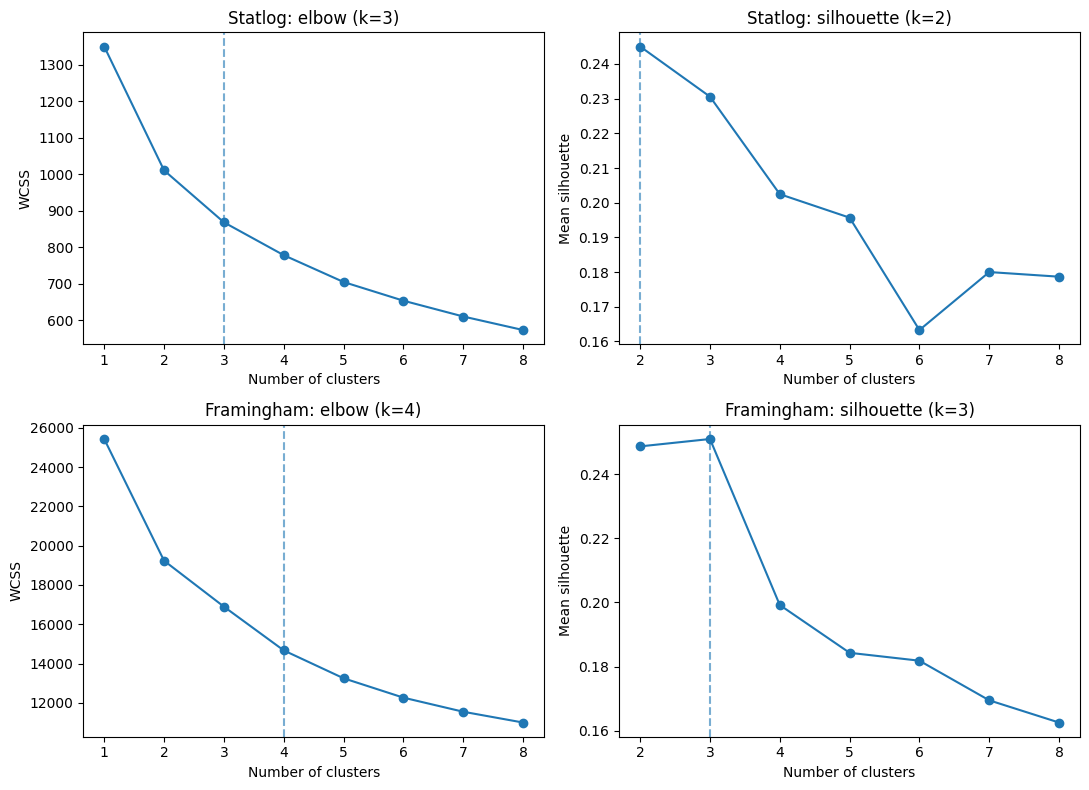

,Dataset,k,WCSS,Silhouette,Min cluster size,Max cluster size
0,Statlog,1,1350.000,NaN,270,270
1,Statlog,2,1010.947,0.245,113,157
2,Statlog,3,868.755,0.231,64,132
3,Statlog,4,778.812,0.202,42,112
4,Statlog,5,705.349,0.196,32,97
5,Statlog,6,654.171,0.163,26,73
6,Statlog,7,610.938,0.180,6,66
7,Statlog,8,573.859,0.179,12,54
8,Framingham,1,25428.000,NaN,4238,4238
9,Framingham,2,19235.685,0.249,1694,2544


In [6]:
scan_rows = []
MODELS, CHOICE = {}, {}
for name, info in DATA.items():
    x = info["X"]
    for k in K_RANGE:
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
        labels = model.fit_predict(x)
        sil = (silhouette_score(x, labels, sample_size=min(SIL_SAMPLE, len(x)),
                                random_state=SEED) if k >= 2 else np.nan)
        counts = np.bincount(labels, minlength=k)
        scan_rows.append({"Dataset": name, "k": k, "WCSS": model.inertia_,
                          "Silhouette": sil, "Min cluster size": int(counts.min()),
                          "Max cluster size": int(counts.max())})
        MODELS[(name, k)] = model

scan = pd.DataFrame(scan_rows)
for name in DATA:
    s = scan[scan.Dataset == name].reset_index(drop=True)
    k_values = s["k"].to_numpy()
    y = s["WCSS"].to_numpy()
    x_scaled = (k_values - k_values.min()) / np.ptp(k_values)
    y_scaled = (y - y.min()) / (y.max() - y.min())
    elbow_score = (1 - x_scaled) - y_scaled
    elbow = int(k_values[np.argmax(elbow_score)])
    best_row = s.loc[s["Silhouette"].idxmax()]
    CHOICE[name] = {"elbow": elbow, "k": int(best_row["k"]),
                    "silhouette": float(best_row["Silhouette"])}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, name in enumerate(DATA):
    s = scan[scan.Dataset == name]
    axes[i, 0].plot(s.k, s.WCSS, "o-")
    axes[i, 0].axvline(CHOICE[name]["elbow"], linestyle="--", alpha=0.6)
    axes[i, 0].set(title=f"{name}: elbow (k={CHOICE[name]['elbow']})",
                   xlabel="Number of clusters", ylabel="WCSS")
    axes[i, 1].plot(s.k, s.Silhouette, "o-")
    axes[i, 1].axvline(CHOICE[name]["k"], linestyle="--", alpha=0.6)
    axes[i, 1].set(title=f"{name}: silhouette (k={CHOICE[name]['k']})",
                   xlabel="Number of clusters", ylabel="Mean silhouette")
plt.tight_layout()
plt.show()
display(scan.round(3))

## 6. Cluster characteristics

The highest-silhouette k was used to inspect cluster sizes and clinical feature profiles. Diagnoses and ten-year CHD labels were examined only afterward. These observed outcome rates describe the groups; they do not measure predictive accuracy or establish causation.

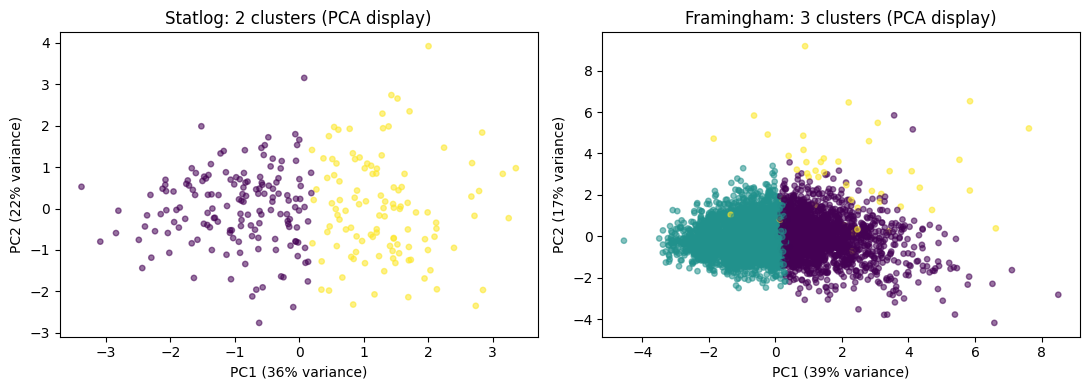

,Dataset,Cluster,Patients,Percent,Positive outcome rate
0,Statlog,0,157,58.148,0.261
1,Statlog,1,113,41.852,0.699
2,Framingham,0,1680,39.641,0.231
3,Framingham,1,2513,59.297,0.093
4,Framingham,2,45,1.062,0.489


,Dataset,Cluster,age,trestbps,chol,thalach,oldpeak,sysBP,diaBP,BMI,totChol,glucose
0,Statlog,0,49.68,124.79,236.17,160.97,0.55,NaN,NaN,NaN,NaN,NaN
1,Statlog,1,61.04,140.45,268.41,133.98,1.74,NaN,NaN,NaN,NaN,NaN
2,Framingham,0,54.65,NaN,NaN,NaN,NaN,150.83,92.24,27.88,255.30,81.51
3,Framingham,1,46.12,NaN,NaN,NaN,NaN,119.67,76.57,24.37,224.15,78.66
4,Framingham,2,54.42,NaN,NaN,NaN,NaN,151.24,87.52,28.11,242.67,249.29


In [7]:
profile_rows, center_rows = [], []
FINAL_LABELS = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, info) in zip(axes, DATA.items()):
    k = CHOICE[name]["k"]
    model = MODELS[(name, k)]
    labels = model.labels_
    FINAL_LABELS[name] = labels
    centers_original = info["scaler"].inverse_transform(model.cluster_centers_)
    for cluster in range(k):
        mask = labels == cluster
        rate = pd.to_numeric(pd.Series(info["outcome"][mask]), errors="coerce").mean()
        profile_rows.append({"Dataset": name, "Cluster": cluster,
                             "Patients": int(mask.sum()), "Percent": 100 * mask.mean(),
                             "Positive outcome rate": rate})
        center_rows.append({"Dataset": name, "Cluster": cluster,
                            **dict(zip(info["features"], centers_original[cluster]))})
    pca = PCA(n_components=2)
    coords = pca.fit_transform(info["X"])
    ax.scatter(coords[:, 0], coords[:, 1], c=labels, s=15, alpha=0.55)
    ax.set(title=f"{name}: {k} clusters (PCA display)",
           xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)",
           ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
plt.tight_layout()
plt.show()
cluster_profile = pd.DataFrame(profile_rows)
cluster_centers = pd.DataFrame(center_rows)
display(cluster_profile.round(3))
display(cluster_centers.round(2))

## 7. Scaling sensitivity

Clustering was repeated with raw, standard, min–max, and robust-scaled features, holding k fixed. Adjusted Rand index (ARI) measures agreement with the standard-scaled partition, accounting for arbitrary cluster numbering. WCSS values are not compared between differently scaled datasets.

In [8]:
scaling_rows = []
for name, info in DATA.items():
    variants = {"Unscaled": info["raw"], "Standard": info["X"],
                "Min–max": MinMaxScaler().fit_transform(info["raw"]),
                "Robust": RobustScaler().fit_transform(info["raw"])}
    k = CHOICE[name]["k"]
    reference = FINAL_LABELS[name]
    for label, x in variants.items():
        fitted = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(x)
        score = silhouette_score(x, fitted.labels_,
                                 sample_size=min(SIL_SAMPLE, len(x)), random_state=SEED)
        scaling_rows.append({"Dataset": name, "Scaling": label, "k": k,
                             "Silhouette": score,
                             "ARI vs standard": adjusted_rand_score(reference, fitted.labels_),
                             "Smallest cluster": int(np.bincount(fitted.labels_).min())})
scaling_results = pd.DataFrame(scaling_rows)
display(scaling_results.round(3))

,Dataset,Scaling,k,Silhouette,ARI vs standard,Smallest cluster
0,Statlog,Unscaled,2,0.382,0.122,102
1,Statlog,Standard,2,0.245,1.000,113
2,Statlog,Min–max,2,0.256,0.725,131
3,Statlog,Robust,2,0.244,0.750,111
4,Framingham,Unscaled,3,0.274,0.092,750
5,Framingham,Standard,3,0.251,1.000,45
6,Framingham,Min–max,3,0.319,0.317,812
7,Framingham,Robust,3,0.237,0.717,45


## 8. Cluster stability

A clustering is more convincing when similar groups appear after moderate changes to the sample. K-means was refitted on eight random 80% subsamples; each fitted model then assigned all patients to clusters. Agreement with the original partition was evaluated using ARI.

In [9]:
rng = np.random.default_rng(SEED)
stability_rows = []
for name, info in DATA.items():
    x = info["X"]
    k = CHOICE[name]["k"]
    reference = FINAL_LABELS[name]
    for repeat in range(8):
        subset = rng.choice(len(x), size=int(0.8 * len(x)), replace=False)
        fit = KMeans(n_clusters=k, n_init=10, random_state=SEED + repeat).fit(x[subset])
        stability_rows.append({"Dataset": name, "Repeat": repeat + 1,
                               "ARI": adjusted_rand_score(reference, fit.predict(x))})
stability_results = pd.DataFrame(stability_rows)
display(stability_results.groupby("Dataset").ARI.agg(["mean", "min", "max"]).round(3))

,mean,min,max
Dataset,,,
Framingham,0.760,0.396,0.985
Statlog,0.872,0.776,0.956


## 9. Individual silhouette scores

A score near 1 indicates good separation; a score near 0 indicates an observation between clusters; a negative score suggests that another cluster may fit better. This analysis also checks whether the mean silhouette hides poorly separated groups.

In [10]:
silhouette_rows = []
for name, info in DATA.items():
    x = info["X"]
    labels = FINAL_LABELS[name]
    rng_local = np.random.default_rng(SEED)
    chosen = rng_local.choice(len(x), size=min(1200, len(x)), replace=False)
    sub_x, sub_labels = x[chosen], labels[chosen]
    # Resample if a small cluster was not represented.
    if len(np.unique(sub_labels)) < 2:
        chosen = np.arange(len(x))
        sub_x, sub_labels = x, labels
    scores = silhouette_samples(sub_x, sub_labels)
    for cluster in sorted(np.unique(sub_labels)):
        vals = scores[sub_labels == cluster]
        silhouette_rows.append({"Dataset": name, "Cluster": int(cluster),
                                "Sample count": len(vals),
                                "Mean silhouette": vals.mean(),
                                "Negative fraction": np.mean(vals < 0)})
silhouette_by_cluster = pd.DataFrame(silhouette_rows)
display(silhouette_by_cluster.round(3))

,Dataset,Cluster,Sample count,Mean silhouette,Negative fraction
0,Statlog,0,157,0.315,0.000
1,Statlog,1,113,0.148,0.106
2,Framingham,0,502,0.147,0.147
3,Framingham,1,687,0.307,0.000
4,Framingham,2,11,0.253,0.182


## 10. Framingham Cluster Sensitivity

The two- and three-cluster solutions were compared because their silhouette scores were nearly identical. Clustering was also repeated without glucose to examine whether this variable substantially influenced the small, high-glucose cluster.

The analysis compares cluster sizes, observed CHD rates, silhouette scores, and agreement between the original and modified partitions.

In [11]:
# Framingham sensitivity analysis

X = DATA["Framingham"]["X"]
y = DATA["Framingham"]["outcome"]

glucose_idx = DATA["Framingham"]["features"].index("glucose")
X_no_glucose = np.delete(X, glucose_idx, axis=1)

labels_2 = MODELS[("Framingham", 2)].labels_
labels_3 = MODELS[("Framingham", 3)].labels_

labels_no_glucose = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=SEED
).fit_predict(X_no_glucose)

comparisons = [
    ("All features, k=2", X, labels_2),
    ("All features, k=3", X, labels_3),
    ("Without glucose, k=3", X_no_glucose, labels_no_glucose)
]

sensitivity_rows = []

for name, features, labels in comparisons:
    sil = silhouette_score(
        features, labels,
        sample_size=min(SIL_SAMPLE, len(features)),
        random_state=SEED
    )

    for cluster in np.unique(labels):
        mask = labels == cluster

        sensitivity_rows.append({
            "Model": name,
            "Cluster": int(cluster),
            "Patients": int(mask.sum()),
            "CHD rate": float(np.mean(y[mask])),
            "Silhouette": sil
        })

sensitivity_results = pd.DataFrame(sensitivity_rows)

display(sensitivity_results.round(3))

print(
    "ARI with vs. without glucose:",
    round(adjusted_rand_score(labels_3, labels_no_glucose), 3)
)

,Model,Cluster,Patients,CHD rate,Silhouette
0,"All features, k=2",0,2544,0.095,0.249
1,"All features, k=2",1,1694,0.238,0.249
2,"All features, k=3",0,1680,0.231,0.251
3,"All features, k=3",1,2513,0.093,0.251
4,"All features, k=3",2,45,0.489,0.251
5,"Without glucose, k=3",0,1681,0.065,0.212
6,"Without glucose, k=3",1,1558,0.177,0.212
7,"Without glucose, k=3",2,999,0.259,0.212


ARI with vs. without glucose: 0.387


In [14]:

from math import sqrt

# Full-data silhouette scores
X = DATA["Framingham"]["X"]
labels_2 = MODELS[("Framingham", 2)].labels_
labels_3 = MODELS[("Framingham", 3)].labels_

for k, labels in [(2, labels_2), (3, labels_3)]:
    score = silhouette_score(X, labels)
    print(f"Framingham k={k}: full-data silhouette = {score:.4f}")

# Relationship between clusters and diabetes
diabetes = SPEC["Framingham"]["df"]["diabetes"].to_numpy()
y = DATA["Framingham"]["outcome"]

cluster_check = pd.DataFrame({
    "Cluster": labels_3,
    "Diabetes": diabetes,
    "CHD": y
})

profile = cluster_check.groupby("Cluster").agg(
    Patients=("CHD", "size"),
    Diabetes_rate=("Diabetes", "mean"),
    CHD_rate=("CHD", "mean")
)

display(profile.round(3))

# Uncertainty around the smallest cluster's CHD rate
def wilson_interval(positive, total):
    z = 1.96
    p = positive / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = z * sqrt(
        p * (1-p) / total + z**2 / (4*total**2)
    ) / denominator
    return center - margin, center + margin

smallest = np.bincount(labels_3).argmin()
mask = labels_3 == smallest

n = int(mask.sum())
positive = int(y[mask].sum())

print("Smallest cluster:", smallest)
print("Patients:", n)
print("CHD cases:", positive)
print("95% Wilson interval:", wilson_interval(positive, n))


Framingham k=2: full-data silhouette = 0.2517
Framingham k=3: full-data silhouette = 0.2539


,Patients,Diabetes_rate,CHD_rate
Cluster,,,
0,1680,0.026,0.231
1,2513,0.008,0.093
2,45,1.000,0.489


Smallest cluster: 2
Patients: 45
CHD cases: 22
95% Wilson interval: (0.3495678935302451, 0.6299577567351026)


## 11. Discussion and Conclusion

The clustering results suggest that cardiovascular measurements can distinguish patient groups with different clinical characteristics, although the quality and stability of these groupings vary between datasets.

For Statlog, the elbow method suggested three clusters, while the highest silhouette score favored two clusters (0.245). The resulting groups contained 157 and 113 patients, with observed heart-disease rates of 26.1% and 69.9%, respectively. The higher-prevalence cluster was older on average and exhibited higher resting blood pressure, cholesterol, and ST-segment depression, alongside lower maximum heart rate. These differences suggest that the selected measurements capture clinically relevant variation in the dataset.

For Framingham, the elbow method suggested four clusters, while the highest silhouette score favored three (0.251). However, the two-cluster solution produced a silhouette score of 0.249, a difference of only 0.002. This provides limited evidence that three clusters are meaningfully better than two.

The Framingham clusters contained 1,680, 2,513, and 45 participants, with observed ten-year CHD rates of 23.1%, 9.3%, and 48.9%, respectively. The smallest cluster represented approximately 1.1% of the dataset and had an unusually high mean glucose level of 249.29. This suggests that extreme glucose measurements may have contributed to the formation of a small, relatively distinct group.

The additional Framingham sensitivity analysis demonstrated that the three-cluster solution depended substantially on glucose. When glucose was excluded, the smallest cluster increased from 45 to 999 participants, and the adjusted Rand index between the original and modified assignments was only 0.387. The revised groups had observed CHD rates of 6.5%, 17.7%, and 25.9%, rather than 23.1%, 9.3%, and 48.9%. This indicates that the original 45-person, high-glucose cluster was strongly influenced by the inclusion of glucose and should not be interpreted as a stable patient subgroup without further validation.

Feature scaling substantially influenced the resulting partitions. Agreement between unscaled and standardized clustering was low, with adjusted Rand index (ARI) values of 0.122 for Statlog and 0.092 for Framingham. Repeated subsampling produced mean ARI values of 0.872 and 0.760, respectively, indicating greater stability in Statlog. Framingham also exhibited a minimum subsample ARI of 0.396, demonstrating that some cluster assignments were sensitive to changes in the sample.

Overall, K-means identified patient groups associated with different observed cardiovascular outcomes, but the modest silhouette scores, preprocessing sensitivity, and small high-glucose cluster limit the strength of these findings. The clusters are exploratory descriptions rather than validated clinical risk categories or evidence of causal relationships.

In [15]:
for name in DATA:
    chosen = CHOICE[name]
    groups = cluster_profile[cluster_profile.Dataset == name]
    stability = stability_results[stability_results.Dataset == name]
    scaler_check = scaling_results[(scaling_results.Dataset == name) &
                                   (scaling_results.Scaling == "Unscaled")].iloc[0]
    print(f"{name}: elbow k={chosen['elbow']}; silhouette k={chosen['k']} "
          f"(mean silhouette={chosen['silhouette']:.3f}).")
    print(f"  Cluster sizes: {groups['Patients'].astype(int).tolist()}; "
          f"outcome rates: {groups['Positive outcome rate'].round(3).tolist()}.")
    print(f"  Subsample stability: mean ARI={stability.ARI.mean():.3f}, "
          f"minimum ARI={stability.ARI.min():.3f}; "
          f"unscaled agreement ARI={scaler_check['ARI vs standard']:.3f}.")

Statlog: elbow k=3; silhouette k=2 (mean silhouette=0.245).
  Cluster sizes: [157, 113]; outcome rates: [0.261, 0.699].
  Subsample stability: mean ARI=0.872, minimum ARI=0.776; unscaled agreement ARI=0.122.
Framingham: elbow k=4; silhouette k=3 (mean silhouette=0.251).
  Cluster sizes: [1680, 2513, 45]; outcome rates: [0.231, 0.093, 0.489].
  Subsample stability: mean ARI=0.760, minimum ARI=0.396; unscaled agreement ARI=0.092.


## References and limitations

**Data:** UCI Statlog (Heart) and Framingham cardiovascular data, as maintained in the [capstone repository](https://github.com/piraterashik/DX799-Data-Science-Capstone).

**Methods:** [Scikit-learn: K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means); [silhouette analysis](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html); [feature preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html).

The two datasets represent different populations and clinical outcomes. Their clusters and silhouette values should be interpreted within each dataset, not as directly comparable patient-risk scores. K-means also assumes relatively compact, Euclidean-shaped groups and can be influenced by outliers.

In [16]:
RESULTS = {
    "week10_eda.csv": eda,
    "week10_k_search.csv": scan,
    "week10_cluster_profiles.csv": cluster_profile,
    "week10_cluster_centers.csv": cluster_centers,
    "week10_scaling.csv": scaling_results,
    "week10_stability.csv": stability_results,
    "week10_silhouette_by_cluster.csv": silhouette_by_cluster,
    "week10_glucose_sensitivity.csv": sensitivity_results
}
for filename, table in RESULTS.items():
    table.to_csv(filename, index=False)